In [1]:
import pandas as pd

file_path = 'wr_games_raw.csv'
df = pd.read_csv(file_path)
print(f"Successfully loaded {len(df):,} rows!")

Successfully loaded 27,962 rows!


In [2]:
# Import required libraries
import tensorflow as tf
import keras
import numpy as np
import psutil
import time
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
keras.utils.set_random_seed(42)

/opt/miniconda3/envs/mynev/lib/python3.11/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [3]:
features = [
    'home', 'targets_avg3', 'rec_avg3', 'yds_avg3', 'td_avg3',
    'targets_avg8', 'rec_avg8', 'yds_avg8', 'yac_avg8',
    'team_pass_att_avg3', 'opp_wr_yds_allowed_avg5', 'opp_pass_def_rank',
    'games_played_career'
]
target = 'receiving_yards'

Train_years = df[df['season'] <= 2023]
Validation_years = df[df['season'] == 2024]
Test_years = df[df['season'] == 2025]

X_train = Train_years[features].fillna(0).values
X_val   = Validation_years[features].fillna(0).values
X_test  = Test_years[features].fillna(0).values

y_train = Train_years[target].values.astype('float32')
y_val   = Validation_years[target].values.astype('float32')
y_test  = Test_years[target].values.astype('float32')

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype('float32')
X_val   = scaler.transform(X_val).astype('float32')
X_test  = scaler.transform(X_test).astype('float32')

BATCH_SIZE = 256

train_dataset = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
                 .shuffle(10000)
                 .batch(BATCH_SIZE)
                 .prefetch(tf.data.AUTOTUNE))

val_dataset = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE))

test_dataset = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE))

In [4]:
model = keras.Sequential([
    keras.layers.Input(shape=(X_train.shape[1],), name='input_features'),
    keras.layers.Dense(128, activation='relu', name='hidden_layer_1'),
    keras.layers.Dense(64, activation='relu', name='hidden_layer_2'),
    keras.layers.Dense(32, activation='relu', name='hidden_layer_3'),
    keras.layers.Dense(1, name='output_receiving_yards')
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mean_squared_error',
    metrics=['mae']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)          │ (None, 128)            │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_2 (Dense)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_3 (Dense)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_receiving_yards (Dense)  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,161 (47.50 KB)

 Trainable params: 12,161 (47.50 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
print("\nStarting CPU via Tensorflow Backend...")
start_time = time.time()

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=30
)

cpu_training_time = time.time() - start_time


Starting CPU via Tensorflow Backend...
Epoch 1/30


/opt/miniconda3/envs/mynev/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 934us/step - loss: 1970.8958 - mae: 31.5524 - val_loss: 1087.4807 - val_mae: 25.0239
Epoch 2/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 558us/step - loss: 1135.9075 - mae: 25.3747 - val_loss: 1019.1029 - val_mae: 23.7332
Epoch 3/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 555us/step - loss: 1096.1469 - mae: 24.8056 - val_loss: 1006.4084 - val_mae: 23.7008
Epoch 4/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 562us/step - loss: 1084.0217 - mae: 24.6746 - val_loss: 1001.4121 - val_mae: 23.5734
Epoch 5/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 553us/step - loss: 1077.7787 - mae: 24.6322 - val_loss: 994.9761 - val_mae: 23.2907
Epoch 6/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 569us/step - loss: 1074.4517 - mae: 24.5482 - val_loss: 987.3846 - val_mae: 23.4166
Epoch 7/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 557us/step - loss: 1072.4972 - mae: 24.5652 - val_loss: 988.4461 - val_mae: 23.2569
Epoch 8/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 563us/step - loss: 1068.9658 - mae: 24.5070 - val_loss: 985.6064 - val_mae: 23.2940
Epoch 9

In [6]:
print("\n" + "="*60)
print("--- COMPREHENSIVE HARDWARE & MODEL PERFORMANCE METRICS ---")
print("="*60)

# Training Throughput & Efficiency
total_samples = len(X_train)
samples_per_sec = total_samples / (cpu_training_time / 30)
print(f"• Training Throughput: {samples_per_sec:.2f} samples/sec")
print(f"• Total Training Time (30 epochs): {cpu_training_time:.2f} seconds")
print(f"• Average Epoch Time: {cpu_training_time / 30:.4f} seconds/epoch")

def run_inference(x):
    return model(x, training=False).numpy()

def time_inference(batch, num_iterations=100):
    for _ in range(10):                      # Warmup runs
        run_inference(batch)
    start_inf = time.time()
    for _ in range(num_iterations):
        run_inference(batch)
    return ((time.time() - start_inf) / num_iterations) * 1000

single_game_latency_ms = time_inference(X_test[:1])      # one game at a time
avg_batch_latency_ms = time_inference(X_test[:32])       # 32 games together
full_season_latency_ms = time_inference(X_test)          # whole 2025 season

print(f"• Inference Latency (Single game prediction): {single_game_latency_ms:.4f} ms")
print(f"• Inference Latency (Batch of 32 games): {avg_batch_latency_ms:.4f} ms "
      f"({avg_batch_latency_ms / 32:.4f} ms/game)")
print(f"• Inference Latency (Full 2025 season, {len(X_test):,} games): {full_season_latency_ms:.4f} ms "
      f"({len(X_test) / (full_season_latency_ms / 1000):,.0f} games/sec)")

# Model Resource Footprint
trainable_count = sum([np.prod(w.shape) for w in model.trainable_weights])
print(f"• Total Trainable Parameters: {trainable_count:,}")
print(f"• Approximate Model Memory Footprint: {(trainable_count * 4) / 1024:.2f} KB (weights only)")

# Regression Accuracy Metrics
val_loss, val_mae = model.evaluate(val_dataset, verbose=0)
print(f"• Validation Loss (MSE): {val_loss:.2f}")
print(f"• Validation MAE: {val_mae:.2f} receiving yards")

# Regression Accuracy Metrics (2025 test season)
test_loss, test_mae = model.evaluate(test_dataset, verbose=0)
print(f"• Test Loss (MSE): {test_loss:.2f}")
print(f"• Test MAE: {test_mae:.2f} receiving yards")

# Baseline to beat
baseline_mae = np.abs(Test_years['yds_avg8'].fillna(y_train.mean()).values - y_test).mean()
print(f"• Baseline MAE (last 8 game averages): {baseline_mae:.2f} receiving yards")

# Classification Metrics (Breakout Game Classification: >= 70 receiving yards)
y_test_preds = np.clip(run_inference(X_test).flatten(), 0, None)
breakout_threshold = 70.0
y_true_binary = (y_test >= breakout_threshold).astype(int)
y_pred_binary = (y_test_preds >= breakout_threshold).astype(int)

acc = accuracy_score(y_true_binary, y_pred_binary)
prec = precision_score(y_true_binary, y_pred_binary, zero_division=0)
rec = recall_score(y_true_binary, y_pred_binary, zero_division=0)
f1 = f1_score(y_true_binary, y_pred_binary, zero_division=0)

print(f"\n--- BREAKOUT GAME CLASSIFICATION METRICS (>= 70 Yards) ---")
print(f"• Classification Accuracy: {acc * 100:.2f}%")
print(f"• Precision: {prec:.4f}")
print(f"• Recall: {rec:.4f}")
print(f"• F1-Score: {f1:.4f}")
print("="*60)


--- COMPREHENSIVE HARDWARE & MODEL PERFORMANCE METRICS ---
• Training Throughput: 324697.73 samples/sec
• Total Training Time (30 epochs): 2.29 seconds
• Average Epoch Time: 0.0764 seconds/epoch
• Inference Latency (Single game prediction): 1.0858 ms
• Inference Latency (Batch of 32 games): 1.0725 ms (0.0335 ms/game)
• Inference Latency (Full 2025 season, 1,462 games): 1.5293 ms (956,011 games/sec)
• Total Trainable Parameters: 12,161
• Approximate Model Memory Footprint: 47.50 KB (weights only)
• Validation Loss (MSE): 988.68
• Validation MAE: 23.65 receiving yards
• Test Loss (MSE): 945.98
• Test MAE: 23.66 receiving yards
• Baseline MAE (last 8 game averages): 23.45 receiving yards

--- BREAKOUT GAME CLASSIFICATION METRICS (>= 70 Yards) ---
• Classification Accuracy: 82.49%
• Precision: 0.5083
• Recall: 0.3552
• F1-Score: 0.4182


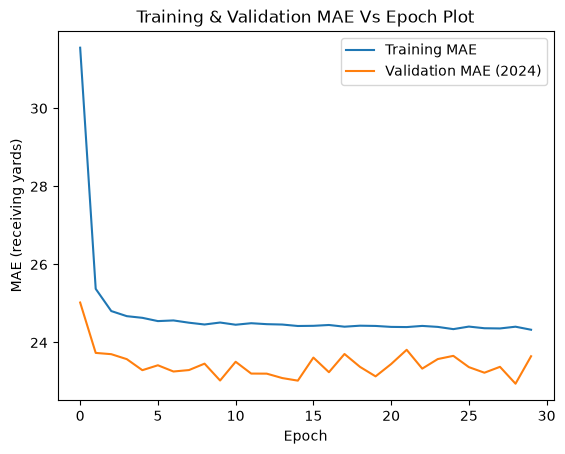

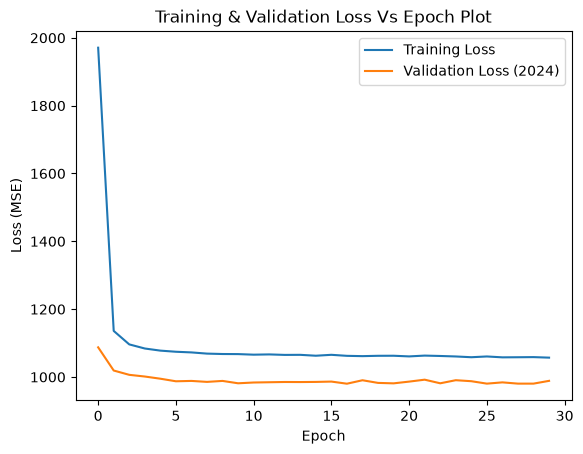

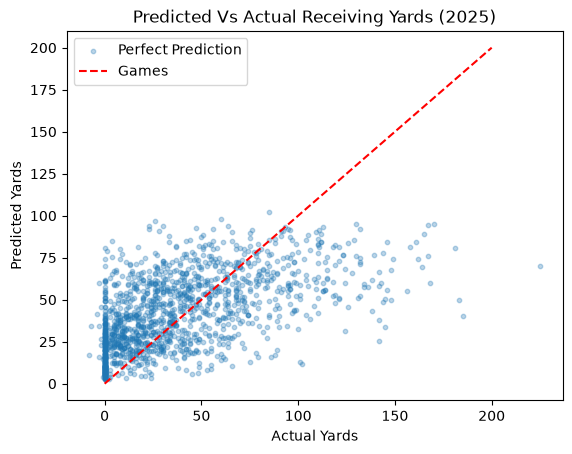

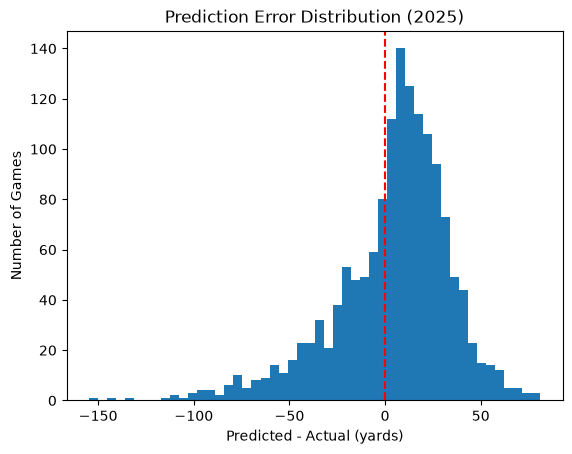

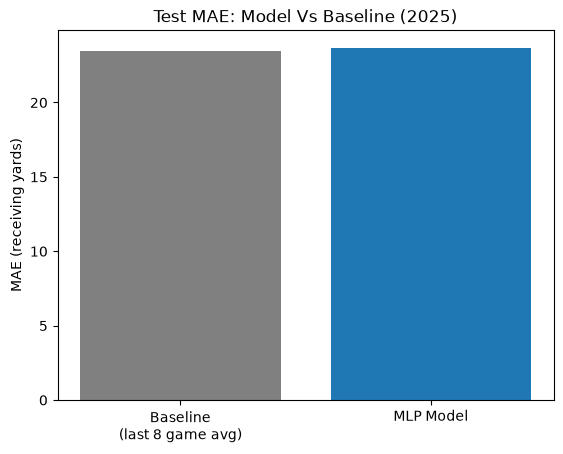

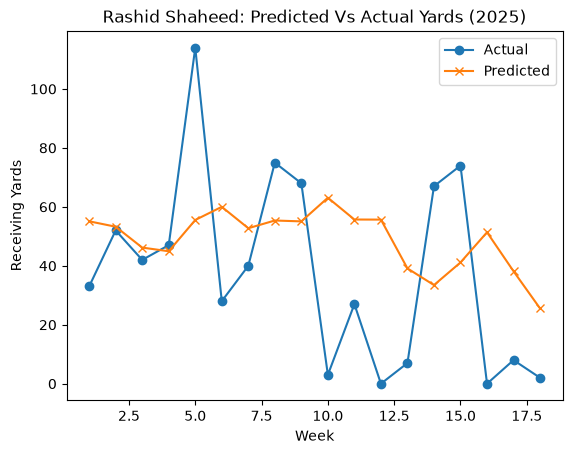

In [7]:
# Training & Validation MAE Vs Epoch Plot
plt.plot(history.history['mae'])
plt.plot(history.history['val_mae'])
plt.title('Training & Validation MAE Vs Epoch Plot')
plt.xlabel('Epoch')
plt.ylabel('MAE (receiving yards)')
plt.legend(['Training MAE', 'Validation MAE (2024)'])
plt.show()

# Training & Validation Loss Vs Epoch Plot
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Training & Validation Loss Vs Epoch Plot')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend(['Training Loss', 'Validation Loss (2024)'])
plt.show()

# Predicted Vs Actual Yards (2025)
plt.scatter(y_test, y_test_preds, alpha=0.3, s=10)
plt.plot([0, 200], [0, 200], 'r--')          # perfect-prediction line
plt.title('Predicted Vs Actual Receiving Yards (2025)')
plt.xlabel('Actual Yards')
plt.ylabel('Predicted Yards')
plt.legend(['Games', 'Perfect Prediction'])
plt.show()

# Prediction Error Distribution (2025)
errors = y_test_preds - y_test
plt.hist(errors, bins=50)
plt.axvline(0, color='r', linestyle='--')
plt.title('Prediction Error Distribution (2025)')
plt.xlabel('Predicted - Actual (yards)')
plt.ylabel('Number of Games')
plt.show()

# Model Vs Baseline MAE
plt.bar(['Baseline\n(last 8 game avg)', 'MLP Model'], [baseline_mae, test_mae], color=['gray', 'tab:blue'])
plt.title('Test MAE: Model Vs Baseline (2025)')
plt.ylabel('MAE (receiving yards)')
plt.show()

# One Player's 2025 Season: Predicted Vs Actual
player = Test_years['player_name'].value_counts().index[0]   # or type a name, e.g. 'Justin Jefferson'
mask = (Test_years['player_name'] == player).values
weeks = Test_years['week'].values[mask]
plt.plot(weeks, y_test[mask], marker='o')
plt.plot(weeks, y_test_preds[mask], marker='x')
plt.title(f'{player}: Predicted Vs Actual Yards (2025)')
plt.xlabel('Week')
plt.ylabel('Receiving Yards')
plt.legend(['Actual', 'Predicted'])
plt.show()